# Sentiment Change Across Crisis Phases
Measure how public sentiment evolves across the 8 crisis phases and within each phase (first 24h vs rest), integrating topic modeling results to trace thematic and emotional trajectories.

## Research Questions
- How does sentiment trend across the 14-day timeline?
- Does outrage decay within a single phase?
- Which phase boundary caused the biggest sentiment shift?
- What topics dominate each phase, and how does their sentiment differ?
- How do topic prevalence and sentiment evolve across phases?
- Does the conversation topic-set reset at each new revelation?
- What archetype (outrage spike, information phase, polarized debate) fits each phase?

## Setup
Import dependencies, configure paths, set random seed for reproducibility.

In [1]:
import ast
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu, kendalltau

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (10, 5)

SEED = 42
np.random.seed(SEED)

OUTPUT_DIR = Path("../output")
PROCESSED_DIR = Path("../../01-preprocessing/output")
DATA_DIR = Path("../../data")
FIGURES_DIR = Path("../../outputs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PHASE_ORDER = [
    "01-the_incident",
    "02-autopsy_request",
    "03-public_outcry",
    "03.1-baldwin_apology",
    "04-scholarships_withdrawal",
    "05-resignation_presscon",
    "06-townhall_podcast",
    "07-uaap_ban",
    "08-legal_probe",
]

PHASE_LABELS = [
    "The Incident",
    "Autopsy Request",
    "Public Outcry",
    "Baldwin Apology",
    "Scholarships Withdrawn",
    "Resignation Press Con",
    "Townhall Podcast",
    "UAAP Ban",
    "Legal Probe",
]

PHASE_DISPLAY = dict(zip(PHASE_ORDER, PHASE_LABELS))

## Crisis Event Timeline
Reference table of actual crisis events anchoring each phase, based on news chronology.

| # | Phase | Event Date | Description |
|---|---|---|---|
| 1 | The Incident | Jun 8, 3:45pm | Drowning of Rene Baterbonia and Divine Adili; initial shock |
| | | Jun 8 evening | Ateneo confirms deaths |
| 2 | Autopsy Request | Jun 9 | Family requests autopsy; Ateneo coordinates with NBI/CIDG |
| 3 | Public Outcry | Jun 11-14 | Viral rumors about "ankle weights" and hazing; podcast debate |
| 3.1 | Podcast | Jun 11-14 | Esguerra podcast episode; calls for probe |
| 3.2 | Accountability | Jun 12 | Baldwin video apology; Baterbonia remains arrive at Ateneo |
| 4 | Scholarships / Withdrawal | Jun 14 | Ateneo de Davao offers scholarships; AdMU withdraws from Filoil |
| 5 | Resignation / Press Con | Jun 15 | Fr. Yap addresses public; accepts Baldwin's resignation |
| 6 | Townhall / Podcast | Jun 16 | Bahay, Espinosa, Bongo townhall; Alas/Reyes on Pia Hontiveros |
| 7 | UAAP Suspension | Jun 19 | UAAP bans Ateneo coaching staff present during trip |
| 8 | Legal Probe | Jun 19+ | CIDG/NBI hearings at Camp Crame; hazing investigation |

These dates anchor the phase boundary annotations in subsequent trajectory plots.

## Event-to-Phase Mapping
Define structured event records for plot annotations and boundary analysis.

In [2]:
# Structured timeline for plot annotations
EVENT_TIMELINE = [
    ("01-the_incident",           "Jun 8",  "Drowning incident; Ateneo confirms deaths"),
    ("02-autopsy_request",        "Jun 9",  "Family requests autopsy; NBI/CIDG coordinate"),
    ("03-public_outcry",           "Jun 11", "Viral rumors: ankle weights, hazing"),
    ("03.1-baldwin_apology",       "Jun 12", "Baldwin video apology; remains arrive"),
    ("04-scholarships_withdrawal", "Jun 14", "Scholarships offered; Filoil withdrawal"),
    ("05-resignation_presscon",    "Jun 15", "Fr. Yap accepts Baldwin's resignation"),
    ("06-townhall_podcast",        "Jun 16", "Team captain townhall; podcast interviews"),
    ("07-uaap_ban",                "Jun 19", "UAAP bans coaching staff"),
    ("08-legal_probe",             "Jun 19", "CIDG/NBI hearings; hazing investigation"),
]

EVENT_DATES = pd.DataFrame(EVENT_TIMELINE, columns=["phase", "event_date_str", "event_description"])
EVENT_DATES["event_date_num"] = pd.to_datetime(EVENT_DATES["event_date_str"], format="%b %d")

phase_boundaries = EVENT_DATES.copy()
phase_boundaries["label"] = phase_boundaries["phase"].map(PHASE_DISPLAY)

print("Phase boundary dates for plot annotations:")
for _, row in phase_boundaries.iterrows():
    print(f"  {row['event_date_str']:12s} | {row['label']:25s} | {row['event_description']}")

Phase boundary dates for plot annotations:
  Jun 8        | The Incident              | Drowning incident; Ateneo confirms deaths
  Jun 9        | Autopsy Request           | Family requests autopsy; NBI/CIDG coordinate
  Jun 11       | Public Outcry             | Viral rumors: ankle weights, hazing
  Jun 12       | Baldwin Apology           | Baldwin video apology; remains arrive
  Jun 14       | Scholarships Withdrawn    | Scholarships offered; Filoil withdrawal
  Jun 15       | Resignation Press Con     | Fr. Yap accepts Baldwin's resignation
  Jun 16       | Townhall Podcast          | Team captain townhall; podcast interviews
  Jun 19       | UAAP Ban                  | UAAP bans coaching staff
  Jun 19       | Legal Probe               | CIDG/NBI hearings; hazing investigation


## Load & Merge Data
Load all 8 scored sentiment files and all available topic-modeling files. Merge by phase into a single unified DataFrame with `phase` and `phase_label` columns.

In [3]:
# Load all scored sentiment files
frames = []
for phase in PHASE_ORDER:
    path = OUTPUT_DIR / f"scored_{phase}.csv"
    if not path.exists():
        print(f"WARNING: {path.name} not found -- skipping")
        continue
    df_batch = pd.read_csv(path, parse_dates=["create_time"])
    df_batch["phase"] = phase
    df_batch["phase_label"] = PHASE_DISPLAY[phase]
    frames.append(df_batch)

df_sentiment = pd.concat(frames, ignore_index=True)
print(f"Loaded sentiment data: {len(df_sentiment):,} comments across {df_sentiment['phase'].nunique()} phases")

Loaded sentiment data: 10,607 comments across 9 phases


In [4]:
# Load all available topic files and merge onto sentiment data
topic_frames = []
for path in sorted(OUTPUT_DIR.glob("topics_*.csv")):
    tt = pd.read_csv(path)
    # Infer phase from filename: topics_01-the_incident.csv -> 01-the_incident
    phase = path.stem.replace("topics_", "")
    tt["phase"] = phase
    topic_frames.append(tt)

df_topics = pd.concat(topic_frames, ignore_index=True)
topic_cols = [c for c in df_topics.columns if c in ("topic_id", "topic_label")]
keep_cols = ["text", "phase"] + topic_cols
keep_cols = [c for c in keep_cols if c in df_topics.columns]
df_topics_sub = df_topics[keep_cols].copy()

# Merge topics onto sentiment data on text + phase
df = df_sentiment.merge(df_topics_sub, on=["text", "phase"], how="left", suffixes=("", "_topic"))

print(f"Merged DataFrame: {len(df):,} rows, {len(df.columns)} columns")
print(f"Columns: {list(df.columns)}")

Merged DataFrame: 10,607 rows, 12 columns
Columns: ['video_id', 'text', 'like_count', 'create_time', 'is_shouting', 'sentences', 'sentiment_label', 'sentiment_score', 'phase', 'phase_label', 'topic_id', 'topic_label']


In [5]:
# Preview the merged data
df.head(3)

,video_id,text,like_count,create_time,is_shouting,sentences,sentiment_label,sentiment_score,phase,phase_label,topic_id,topic_label
0,GhAzUZ_IDBM,pinatay tlga yan.. ayo kong maniwala na naluno...,0,2026-06-23 00:00:00+00:00,0,['pinatay tlga yan.. ayo kong maniwala na nalu...,NEGATIVE,0.940838,01-the_incident,The Incident,0,Drowning Incident
1,GhAzUZ_IDBM,paano namin makita kapag blurr,0,2026-06-22 00:00:00+00:00,0,['paano namin makita kapag blurr'],NEUTRAL,0.560730,01-the_incident,The Incident,5,Video Evidence Inquiry
2,GhAzUZ_IDBM,may binura na yan kasi c baldwin ang operator eh,0,2026-06-22 00:00:00+00:00,0,['may binura na yan kasi c baldwin ang operato...,NEGATIVE,0.463464,01-the_incident,The Incident,-1,NaN


In [6]:
# Check data quality: missing values, timestamp range, phase sizes
print(f"Rows with missing sentiment_label: {df['sentiment_label'].isna().sum()}")
print(f"Rows with missing topic_label: {df['topic_label'].isna().sum()}")
print()
print(f"Timestamp range: {df['create_time'].min()} to {df['create_time'].max()}")
print(f"Unique dates: {df['create_time'].dt.date.nunique()}")
print()
print("Comments per phase:")
for p in PHASE_ORDER:
    n = (df['phase'] == p).sum()
    if n > 0:
        print(f"  {PHASE_DISPLAY[p]:35s} {n:5,}")

Rows with missing sentiment_label: 2
Rows with missing topic_label: 3382

Timestamp range: 2026-06-10 00:00:00+00:00 to 2026-06-24 04:19:00+00:00
Unique dates: 15

Comments per phase:
  The Incident                          857
  Autopsy Request                     2,399
  Public Outcry                         254
  Baldwin Apology                       752
  Scholarships Withdrawn                542
  Resignation Press Con                 309
  Townhall Podcast                    5,135
  UAAP Ban                              100
  Legal Probe                           259


## Daily Sentiment Trajectory
Resample by calendar date, compute polarity index and percent negative. Smooth with a 3-day rolling average and overlay phase boundaries as vertical lines. Test for monotonic trend using the Mann-Kendall test.

In [7]:
# Aggregate sentiment by calendar date
df["date"] = df["create_time"].dt.date

daily = (
    df.groupby("date")
    .agg(
        total_comments=("sentiment_label", "count"),
        n_negative=("sentiment_label", lambda x: (x == "NEGATIVE").sum()),
        n_positive=("sentiment_label", lambda x: (x == "POSITIVE").sum()),
        n_neutral=("sentiment_label", lambda x: (x == "NEUTRAL").sum()),
    )
    .reset_index()
)

daily["pct_negative"] = daily["n_negative"] / daily["total_comments"] * 100
daily["pct_positive"] = daily["n_positive"] / daily["total_comments"] * 100
daily["pct_neutral"] = daily["n_neutral"] / daily["total_comments"] * 100
daily["polarity_index"] = daily["pct_positive"] - daily["pct_negative"]

# 3-day rolling average for smoothing
daily["polarity_rolling"] = daily["polarity_index"].rolling(3, min_periods=1).mean()
daily["pct_neg_rolling"] = daily["pct_negative"].rolling(3, min_periods=1).mean()

# Phase date ranges for shaded region annotations
phase_ranges = (
    df.groupby("phase")["create_time"]
    .agg(["min", "max"])
    .reset_index()
    .sort_values("min")
)
phase_ranges["label"] = phase_ranges["phase"].map(PHASE_DISPLAY)

daily.head()

,date,total_comments,n_negative,n_positive,n_neutral,pct_negative,pct_positive,pct_neutral,polarity_index,polarity_rolling,pct_neg_rolling
0,2026-06-10,639,492,28,119,76.995305,4.381847,18.622848,-72.613459,-72.613459,76.995305
1,2026-06-11,643,453,30,160,70.451011,4.665630,24.883359,-65.785381,-69.199420,73.723158
2,2026-06-12,267,189,18,60,70.786517,6.741573,22.471910,-64.044944,-67.481261,72.744278
3,2026-06-13,835,613,62,160,73.413174,7.425150,19.161677,-65.988024,-65.272783,71.550234
4,2026-06-14,425,303,34,88,71.294118,8.000000,20.705882,-63.294118,-64.442362,71.831269


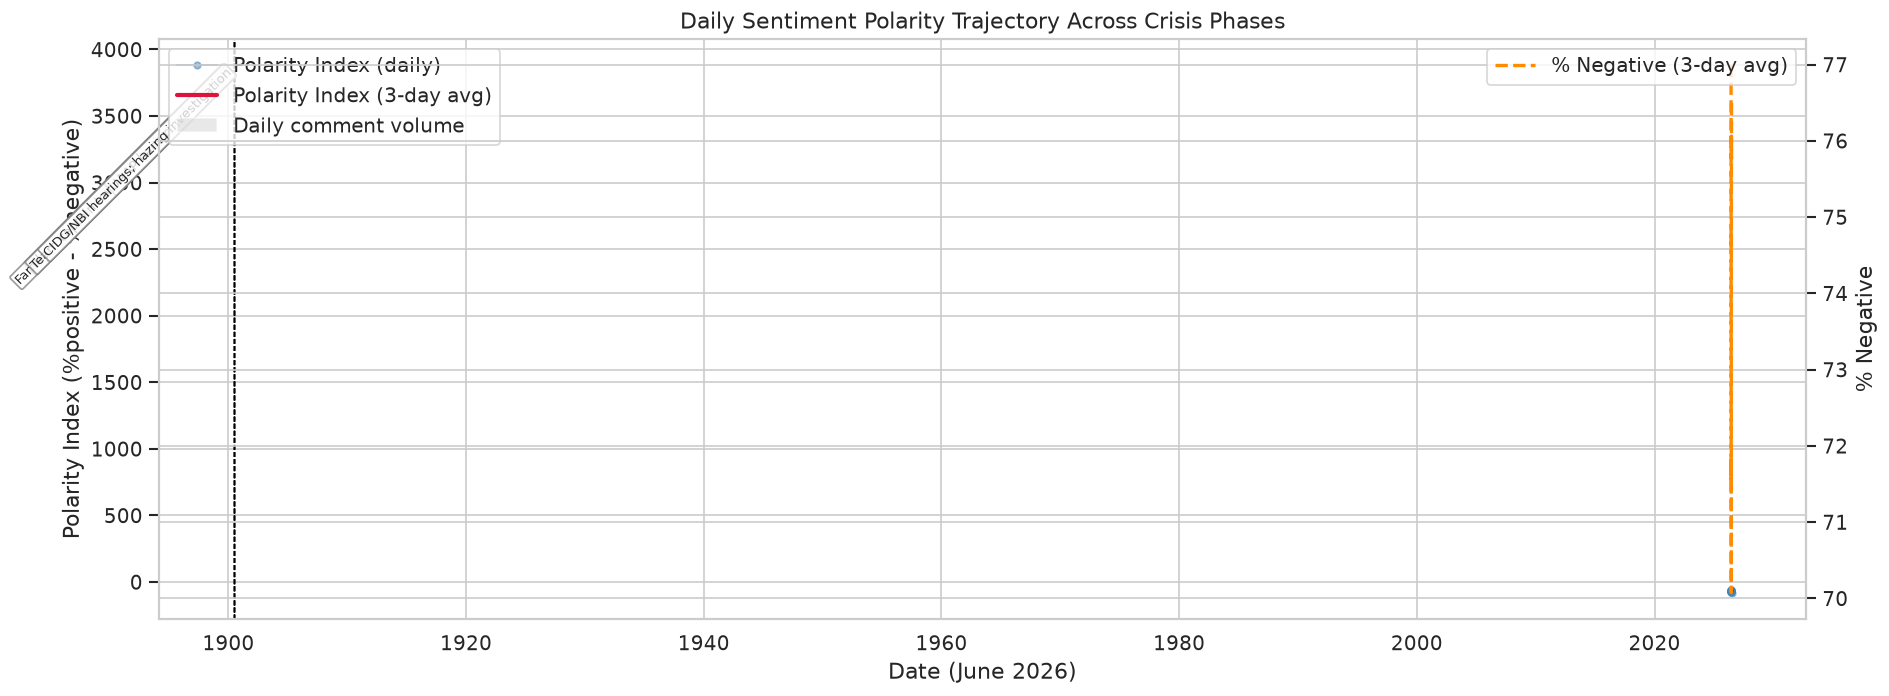

In [8]:
# Dual-axis plot: Polarity Index (line) + comment volume (bars)
fig, ax1 = plt.subplots(figsize=(16, 6))

dates = pd.to_datetime(daily["date"])

# Bar chart: daily comment volume (proxy for public attention)
ax1.bar(dates, daily["total_comments"], color="lightgray", alpha=0.5,
        label="Daily comment volume", zorder=1)

# Line: raw polarity index
ax1.plot(dates, daily["polarity_index"], color="steelblue", linewidth=1.2,
         alpha=0.5, marker="o", markersize=4, label="Polarity Index (daily)", zorder=3)

# Line: 3-day rolling average
ax1.plot(dates, daily["polarity_rolling"], color="crimson", linewidth=2.5,
         label="Polarity Index (3-day avg)", zorder=4)

# Phase boundary vertical lines with event descriptions
for _, row in phase_boundaries.iterrows():
    bd = row["event_date_num"]
    ax1.axvline(x=bd, color="black", linestyle="--", linewidth=0.8, alpha=0.6, zorder=2)
    ax1.text(bd, ax1.get_ylim()[1] * 0.95, row["event_description"],
             rotation=45, fontsize=7.5, ha="right", va="top",
             bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="gray", alpha=0.8))

ax1.set_xlabel("Date (June 2026)")
ax1.set_ylabel("Polarity Index (%positive - %negative)")
ax1.set_title("Daily Sentiment Polarity Trajectory Across Crisis Phases")
ax1.legend(loc="upper left")

# Second axis: percent negative rolling
ax2 = ax1.twinx()
ax2.plot(dates, daily["pct_neg_rolling"], color="darkorange", linewidth=2,
         linestyle="--", label="% Negative (3-day avg)", zorder=4)
ax2.set_ylabel("% Negative")
ax2.legend(loc="upper right")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "daily_sentiment_trajectory.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Mann-Kendall test for monotonic trend in daily Polarity Index
tau, p_value = kendalltau(daily["polarity_index"], np.arange(len(daily)))

print("Mann-Kendall Trend Test - Daily Polarity Index")
print(f"  Kendall's tau: {tau:.4f}")
print(f"  p-value:       {p_value:.4f}")
print()

if p_value < 0.05:
    direction = "increasing" if tau > 0 else "decreasing"
    print(f"Statistically significant {direction} trend (p < 0.05).")
    print(f"Sentiment polarity is {'rising' if tau > 0 else 'falling'} across the crisis timeline.")
else:
    print("No statistically significant monotonic trend detected.")
    print("Sentiment polarity fluctuates but does not consistently trend in one direction.")

Mann-Kendall Trend Test - Daily Polarity Index
  Kendall's tau: -0.1810
  p-value:       0.3795

No statistically significant monotonic trend detected.
Sentiment polarity fluctuates but does not consistently trend in one direction.


## Phase-Level Sentiment Trajectory
Aggregate by phase to compare overall sentiment across crisis events. Rank phases by negativity and plot the polarity trajectory to identify escalation or de-escalation patterns.

In [10]:
# Aggregate sentiment by phase
phase_agg = (
    df.groupby("phase")
    .agg(
        total_comments=("sentiment_label", "count"),
        n_negative=("sentiment_label", lambda x: (x == "NEGATIVE").sum()),
        n_positive=("sentiment_label", lambda x: (x == "POSITIVE").sum()),
        n_neutral=("sentiment_label", lambda x: (x == "NEUTRAL").sum()),
        mean_likes=("like_count", "mean"),
    )
    .reset_index()
)

phase_agg["pct_negative"] = phase_agg["n_negative"] / phase_agg["total_comments"] * 100
phase_agg["pct_positive"] = phase_agg["n_positive"] / phase_agg["total_comments"] * 100
phase_agg["pct_neutral"] = phase_agg["n_neutral"] / phase_agg["total_comments"] * 100
phase_agg["polarity_index"] = phase_agg["pct_positive"] - phase_agg["pct_negative"]
phase_agg["label"] = phase_agg["phase"].map(PHASE_DISPLAY)
phase_agg["event_date"] = phase_agg["phase"].map(
    dict(zip(EVENT_DATES["phase"], EVENT_DATES["event_date_str"]))
)

# Sort by phase order
phase_agg["phase_num"] = phase_agg["phase"].map(
    {p: i for i, p in enumerate(PHASE_ORDER)}
)
phase_agg = phase_agg.sort_values("phase_num").reset_index(drop=True)

print("Sentiment per phase (sorted chronologically):")
display(phase_agg[["label", "event_date", "total_comments",
                    "pct_negative", "pct_positive", "pct_neutral",
                    "polarity_index", "mean_likes"]].round(1))

Sentiment per phase (sorted chronologically):


,label,event_date,total_comments,pct_negative,pct_positive,pct_neutral,polarity_index,mean_likes
0,The Incident,Jun 8,857,71.5,5.0,23.5,-66.5,2.4
1,Autopsy Request,Jun 9,2399,77.9,3.8,18.3,-74.2,1.9
2,Public Outcry,Jun 11,254,67.7,10.6,21.7,-57.1,1.0
3,Baldwin Apology,Jun 12,752,77.1,6.6,16.2,-70.5,2.2
4,Scholarships Withdrawn,Jun 14,542,58.7,16.8,24.5,-41.9,2.7
5,Resignation Press Con,Jun 15,309,79.0,4.5,16.5,-74.4,2.1
6,Townhall Podcast,Jun 16,5134,73.5,7.4,19.0,-66.1,3.6
7,UAAP Ban,Jun 19,100,53.0,32.0,15.0,-21.0,3.0
8,Legal Probe,Jun 19,258,72.9,7.0,20.2,-65.9,1.4


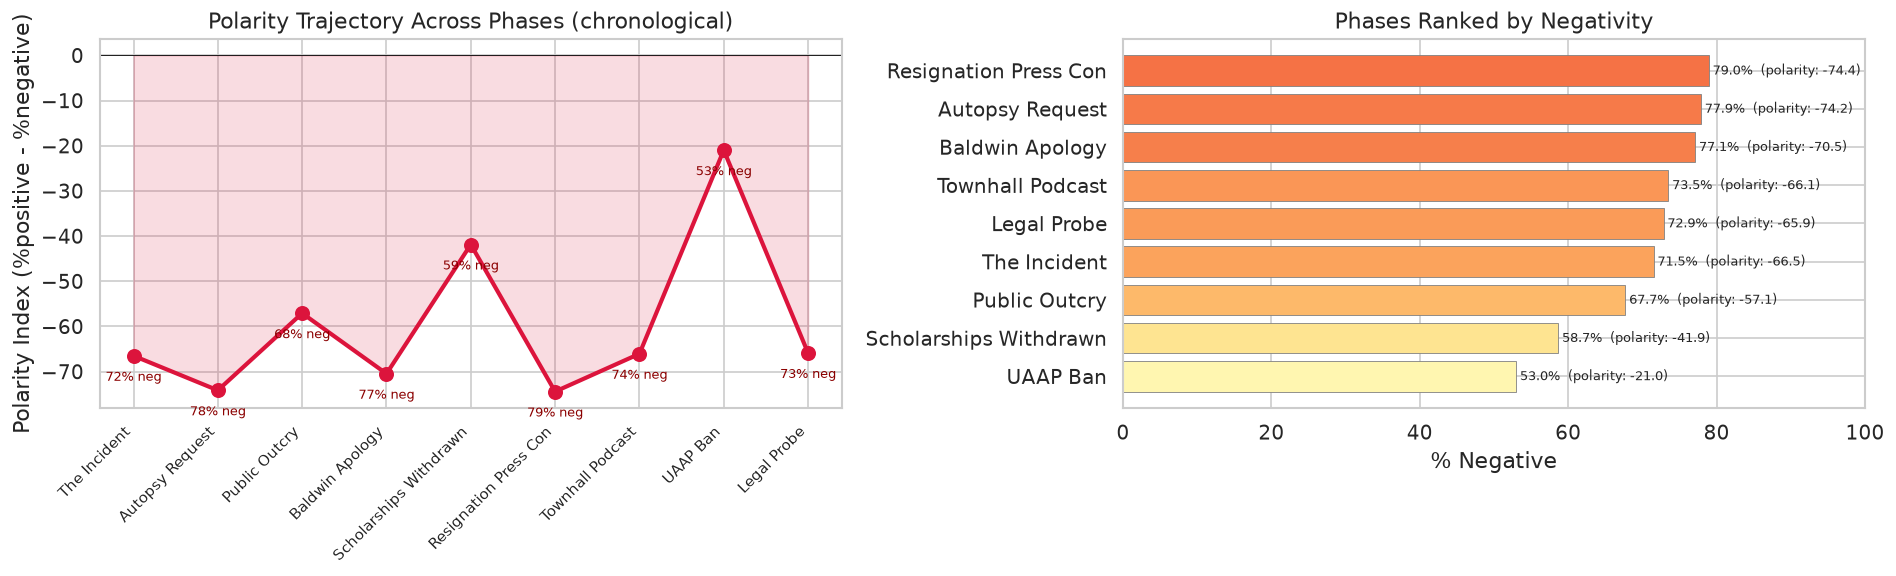

In [11]:
# Phase trajectory: Polarity Index across phases
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Left: Polarity Index trajectory (line plot)
x = np.arange(len(phase_agg))
ax1.plot(x, phase_agg["polarity_index"], color="crimson", linewidth=2.5,
         marker="o", markersize=8, zorder=3)
ax1.fill_between(x, phase_agg["polarity_index"], 0,
                 where=(phase_agg["polarity_index"] < 0),
                 color="crimson", alpha=0.15)
ax1.axhline(y=0, color="black", linewidth=0.5)
ax1.set_xticks(x)
ax1.set_xticklabels(phase_agg["label"], rotation=45, ha="right", fontsize=9)
ax1.set_ylabel("Polarity Index (%positive - %negative)")
ax1.set_title("Polarity Trajectory Across Phases (chronological)")

# Annotate each point with %negative
for _, row in phase_agg.iterrows():
    ax1.annotate(f"{row['pct_negative']:.0f}% neg",
                 (row["phase_num"], row["polarity_index"]),
                 textcoords="offset points", xytext=(0, -15),
                 ha="center", fontsize=8, color="darkred")

# Right: Ranked by negativity (bar chart)
phase_sorted = phase_agg.sort_values("pct_negative", ascending=True)
colors = plt.cm.RdYlGn_r(phase_sorted["pct_negative"] / 100)
bars = ax2.barh(phase_sorted["label"], phase_sorted["pct_negative"],
                color=colors, edgecolor="gray", linewidth=0.5)

# Annotate bars with polarity index
for bar, val, pol in zip(bars, phase_sorted["pct_negative"], phase_sorted["polarity_index"]):
    ax2.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
             f"{val:.1f}%  (polarity: {pol:.1f})",
             va="center", fontsize=8)

ax2.set_xlabel("% Negative")
ax2.set_title("Phases Ranked by Negativity")
ax2.set_xlim(0, 100)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase_sentiment_trajectory.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Which phase is most / least negative
most_neg = phase_agg.loc[phase_agg["pct_negative"].idxmax()]
least_neg = phase_agg.loc[phase_agg["pct_negative"].idxmin()]

print(f"Most negative phase:  {most_neg['label']}  ({most_neg['pct_negative']:.1f}% negative, "
      f"polarity {most_neg['polarity_index']:.1f})")
print(f"Least negative phase: {least_neg['label']}  ({least_neg['pct_negative']:.1f}% negative, "
      f"polarity {least_neg['polarity_index']:.1f})")
print()

# Polarity range across phases
print(f"Polarity range: {phase_agg['polarity_index'].min():.1f} to "
      f"{phase_agg['polarity_index'].max():.1f} "
      f"(delta = {phase_agg['polarity_index'].max() - phase_agg['polarity_index'].min():.1f})")
print()

# Volume-weighted polarity
weighted_pol = (phase_agg['polarity_index'] * phase_agg['total_comments']).sum() / phase_agg['total_comments'].sum()
print(f"Volume-weighted avg polarity: {weighted_pol:.1f}")

Most negative phase:  Resignation Press Con  (79.0% negative, polarity -74.4)
Least negative phase: UAAP Ban  (53.0% negative, polarity -21.0)

Polarity range: -74.4 to -21.0 (delta = 53.4)

Volume-weighted avg polarity: -66.6


## Within-Phase: Day 1 vs Rest
For each phase, compare sentiment on the first date (when the revelation breaks) to all subsequent dates. Tests whether initial outrage decays or sustains over time using chi-square and Cramer's V.

In [13]:
# For each phase, find the earliest date and split into Day 1 vs Rest
phase_day1 = []

for phase in df["phase"].unique():
    phase_df = df[df["phase"] == phase].copy()
    phase_df["date"] = phase_df["create_time"].dt.date
    earliest = phase_df["date"].min()

    day1 = phase_df[phase_df["date"] == earliest]
    rest = phase_df[phase_df["date"] > earliest]

    def sentiment_dist(subset, label):
        neg = (subset["sentiment_label"] == "NEGATIVE").sum()
        pos = (subset["sentiment_label"] == "POSITIVE").sum()
        neu = (subset["sentiment_label"] == "NEUTRAL").sum()
        total = len(subset)
        return {
            "phase": phase,
            "label": PHASE_DISPLAY[phase],
            "window": label,
            "total": total,
            "pct_neg": neg / total * 100 if total else 0,
            "pct_pos": pos / total * 100 if total else 0,
            "pct_neu": neu / total * 100 if total else 0,
            "polarity": (pos - neg) / total * 100 if total else 0,
        }

    phase_day1.append(sentiment_dist(day1, "Day 1"))
    if len(rest) > 0:
        phase_day1.append(sentiment_dist(rest, "Rest"))

day1_df = pd.DataFrame(phase_day1)
# Sort by phase order then window
day1_df["phase_num"] = day1_df["phase"].map(
    {p: i for i, p in enumerate(PHASE_ORDER)}
)
day1_df = day1_df.sort_values(["phase_num", "window"]).reset_index(drop=True)

display(
    day1_df[["label", "window", "total", "pct_neg", "pct_pos", "pct_neu", "polarity"]].round(1)
)

,label,window,total,pct_neg,pct_pos,pct_neu,polarity
0,The Incident,Day 1,172,69.2,7.0,23.8,-62.2
1,The Incident,Rest,685,72.1,4.5,23.4,-67.6
2,Autopsy Request,Day 1,467,79.9,3.4,16.7,-76.4
3,Autopsy Request,Rest,1932,77.4,3.8,18.7,-73.6
4,Public Outcry,Day 1,63,68.3,4.8,27.0,-63.5
5,Public Outcry,Rest,191,67.5,12.6,19.9,-55.0
6,Baldwin Apology,Day 1,499,76.2,7.4,16.4,-68.7
7,Baldwin Apology,Rest,253,79.1,5.1,15.8,-73.9
8,Scholarships Withdrawn,Day 1,11,90.9,9.1,0.0,-81.8
9,Scholarships Withdrawn,Rest,531,58.0,16.9,25.0,-41.1


In [14]:
# Chi-square test per phase: is Day 1 sentiment different from Rest?
print("Within-phase comparison: Day 1 vs Rest")
header = f"{'Phase':30s} {'Day1 N':>6s} {'Rest N':>6s} {'Chi2':>8s} {'p':>8s} {'Cramer V':>8s} {'Sig?':>6s}"
print(header)
print("-" * 75)

results = []
for phase in day1_df["phase"].unique():
    pair = day1_df[day1_df["phase"] == phase]
    if len(pair) < 2:
        continue

    day1_row = pair[pair["window"] == "Day 1"].iloc[0]
    rest_row = pair[pair["window"] == "Rest"].iloc[0]

    contingency = np.array([
        [day1_row["pct_neg"] * day1_row["total"] / 100,
         day1_row["pct_pos"] * day1_row["total"] / 100,
         day1_row["pct_neu"] * day1_row["total"] / 100],
        [rest_row["pct_neg"] * rest_row["total"] / 100,
         rest_row["pct_pos"] * rest_row["total"] / 100,
         rest_row["pct_neu"] * rest_row["total"] / 100],
    ])

    chi2, p, _, _ = chi2_contingency(contingency)
    n = contingency.sum()
    cramer_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))

    sig = "YES" if p < 0.05 else "no"
    results.append({
        "phase": phase,
        "label": PHASE_DISPLAY[phase],
        "day1_n": int(day1_row["total"]),
        "rest_n": int(rest_row["total"]),
        "delta_neg": rest_row["pct_neg"] - day1_row["pct_neg"],
        "delta_polarity": rest_row["polarity"] - day1_row["polarity"],
        "chi2": chi2,
        "p": p,
        "cramer_v": cramer_v,
        "significant": sig,
    })

    print(
        f"{PHASE_DISPLAY[phase]:30s} {int(day1_row['total']):6d} "
        f"{int(rest_row['total']):6d} {chi2:8.2f} {p:8.4f} {cramer_v:8.4f} {sig:>6s}"
    )

results_df = pd.DataFrame(results)
print()
print("Delta interpretation:")
print("  delta_neg = Rest %neg - Day1 %neg (positive = outrage decays)")
print("  delta_polarity = Rest polarity - Day1 polarity (positive = sentiment improves)")


Within-phase comparison: Day 1 vs Rest
Phase                          Day1 N Rest N     Chi2        p Cramer V   Sig?
---------------------------------------------------------------------------
The Incident                      172    685     1.82   0.4015   0.0461     no
Autopsy Request                   467   1932     1.30   0.5221   0.0233     no
Public Outcry                      63    191     3.82   0.1483   0.1226     no
Baldwin Apology                   499    253     1.53   0.4650   0.0451     no
Scholarships Withdrawn             11    531     5.14   0.0765   0.0974     no
Resignation Press Con             155    154     1.85   0.3971   0.0773     no
Townhall Podcast                 3538   1597    13.35   0.0013   0.0510    YES
UAAP Ban                           39     61     0.63   0.7308   0.0792     no
Legal Probe                        13    246     0.20   0.9069   0.0275     no

Delta interpretation:
  delta_neg = Rest %neg - Day1 %neg (positive = outrage decays)
  delta_

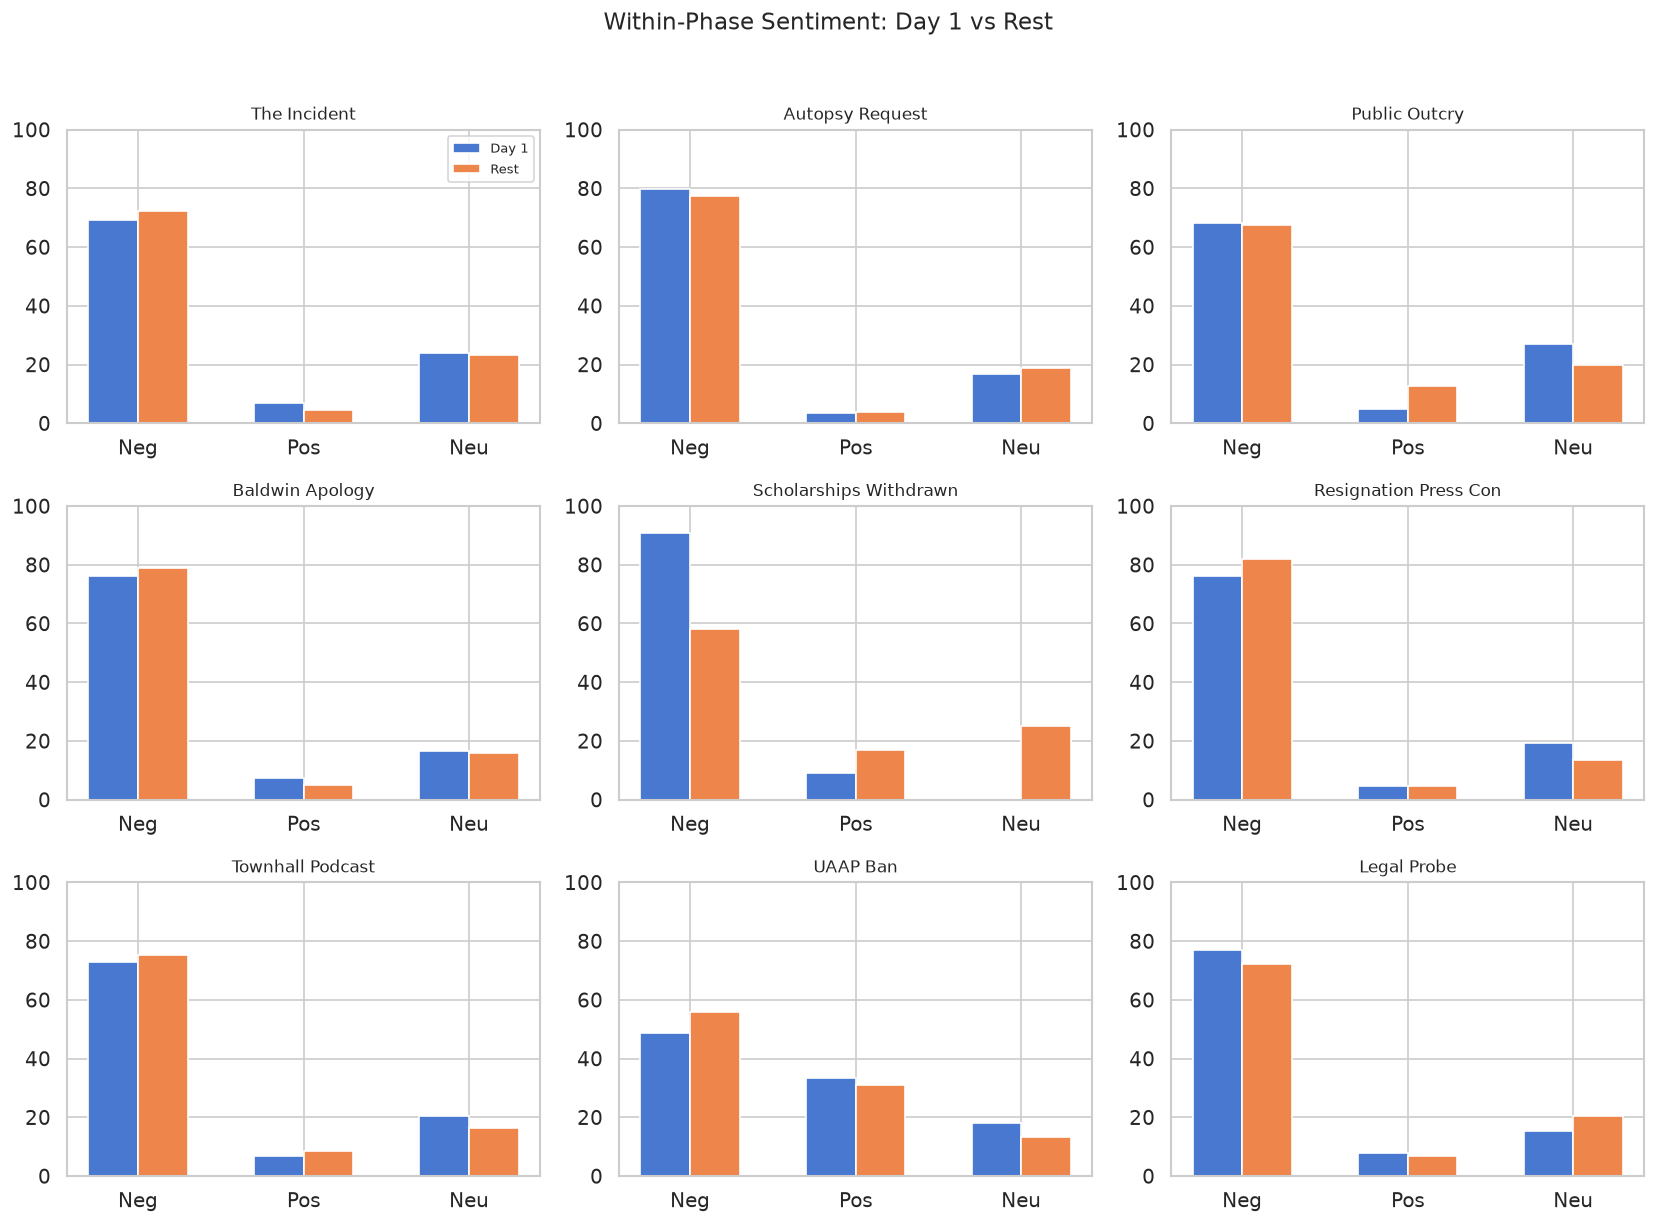

In [15]:
# Faceted bar chart: 9 panels, each showing Day1 vs Rest
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for idx, phase in enumerate(PHASE_ORDER):
    ax = axes[idx]
    pair = day1_df[day1_df["phase"] == phase]
    if len(pair) == 0:
        ax.set_visible(False)
        continue

    x = np.arange(3)
    width = 0.3

    for i, w in enumerate(["Day 1", "Rest"]):
        row = pair[pair["window"] == w]
        if len(row) == 0:
            continue
        vals = [row["pct_neg"].values[0], row["pct_pos"].values[0], row["pct_neu"].values[0]]
        ax.bar(x + i * width, vals, width, label=w if idx == 0 else None)

    ax.set_xticks(x + width / 2)
    ax.set_xticklabels(["Neg", "Pos", "Neu"])
    ax.set_title(PHASE_DISPLAY[phase], fontsize=10)
    ax.set_ylim(0, 100)
    if idx == 0:
        ax.legend(fontsize=8)

fig.suptitle("Within-Phase Sentiment: Day 1 vs Rest", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "day1_vs_rest_faceted.png", dpi=150, bbox_inches="tight")
plt.show()


In [16]:
# Which phases show the biggest within-phase shift
results_df["abs_delta_neg"] = results_df["delta_neg"].abs()
shifted = results_df.sort_values("abs_delta_neg", ascending=False)

print("Biggest within-phase sentiment shifts:")
for _, row in shifted.iterrows():
    arrow = chr(8593) if row["delta_neg"] > 0 else chr(8595)
    print(
        f"  {row['label']:30s} {arrow} {abs(row['delta_neg']):.1f}pp neg "
        f"(p={row['p']:.4f}, V={row['cramer_v']:.3f})"
    )

sig_count = (results_df["p"] < 0.05).sum()
print(f"Phases with significant Day 1 / Rest difference: {sig_count}/{len(results_df)}")


Biggest within-phase sentiment shifts:
  Scholarships Withdrawn         ↓ 32.9pp neg (p=0.0765, V=0.097)
  UAAP Ban                       ↑ 7.0pp neg (p=0.7308, V=0.079)
  Resignation Press Con          ↑ 5.7pp neg (p=0.3971, V=0.077)
  Legal Probe                    ↓ 4.6pp neg (p=0.9069, V=0.028)
  The Incident                   ↑ 2.9pp neg (p=0.4015, V=0.046)
  Baldwin Apology                ↑ 2.9pp neg (p=0.4650, V=0.045)
  Autopsy Request                ↓ 2.4pp neg (p=0.5221, V=0.023)
  Townhall Podcast               ↑ 2.4pp neg (p=0.0013, V=0.051)
  Public Outcry                  ↓ 0.7pp neg (p=0.1483, V=0.123)
Phases with significant Day 1 / Rest difference: 1/9


## Phase Boundary Sentiment Shifts
For each adjacent phase transition, compare sentiment in the 3 days before vs 3 days after the boundary. Quantifies which revelations actually moved public sentiment using Mann-Whitney U tests.

In [17]:
# For each adjacent phase boundary, compare sentiment before vs after
boundaries = []

for i in range(len(PHASE_ORDER) - 1):
    phase_a = PHASE_ORDER[i]
    phase_b = PHASE_ORDER[i + 1]

    # Find boundary date: the first comment date of phase_b
    boundary_date = df[df["phase"] == phase_b]["create_time"].min()
    label_a = PHASE_DISPLAY[phase_a]
    label_b = PHASE_DISPLAY[phase_b]

    # 3-day window before and after boundary
    window_start = boundary_date - pd.Timedelta(days=3)
    window_end = boundary_date + pd.Timedelta(days=3)

    before = df[(df["create_time"] >= window_start) & (df["create_time"] < boundary_date)]
    after = df[(df["create_time"] >= boundary_date) & (df["create_time"] <= window_end)]

    if len(before) == 0 or len(after) == 0:
        continue

    def polarity(subset):
        neg = (subset["sentiment_label"] == "NEGATIVE").sum()
        pos = (subset["sentiment_label"] == "POSITIVE").sum()
        total = len(subset)
        return (pos - neg) / total * 100 if total else 0

    pol_before = polarity(before)
    pol_after = polarity(after)
    pct_neg_before = (before["sentiment_label"] == "NEGATIVE").sum() / len(before) * 100
    pct_neg_after = (after["sentiment_label"] == "NEGATIVE").sum() / len(after) * 100

    # Mann-Whitney U on sentiment scores
    scores_before = before["sentiment_score"].values
    scores_after = after["sentiment_score"].values
    u_stat, p_value = mannwhitneyu(scores_before, scores_after, alternative="two-sided")

    boundaries.append({
        "transition": f"{label_a}  >>>  {label_b}",
        "boundary_date": boundary_date,
        "n_before": len(before),
        "n_after": len(after),
        "pol_before": pol_before,
        "pol_after": pol_after,
        "delta_pol": pol_after - pol_before,
        "pct_neg_before": pct_neg_before,
        "pct_neg_after": pct_neg_after,
        "delta_neg": pct_neg_after - pct_neg_before,
        "u_stat": u_stat,
        "p_value": p_value,
    })

boundary_df = pd.DataFrame(boundaries)

print("Phase boundary sentiment shifts (3d before vs 3d after):")
print()
display(
    boundary_df[["transition", "n_before", "n_after", "pol_before", "pol_after",
                 "delta_pol", "delta_neg", "p_value"]].round(2)
)

Phase boundary sentiment shifts (3d before vs 3d after):



,transition,n_before,n_after,pol_before,pol_after,delta_pol,delta_neg,p_value
0,Autopsy Request >>> Public Outcry,1282,1817,-69.19,-63.79,5.40,-2.44,0.94
1,Public Outcry >>> Baldwin Apology,1549,1969,-68.30,-64.70,3.60,-1.19,0.88
2,Baldwin Apology >>> Scholarships Withdrawn,1549,1969,-68.30,-64.70,3.60,-1.19,0.88
3,Scholarships Withdrawn >>> Resignation Press...,1550,6172,-63.74,-66.61,-2.87,2.43,NaN
4,Resignation Press Con >>> Townhall Podcast,1134,6097,-63.76,-66.49,-2.74,2.84,NaN
5,Townhall Podcast >>> UAAP Ban,5753,1183,-66.49,-67.71,-1.22,2.26,NaN
6,UAAP Ban >>> Legal Probe,1550,6172,-63.74,-66.61,-2.87,2.43,NaN


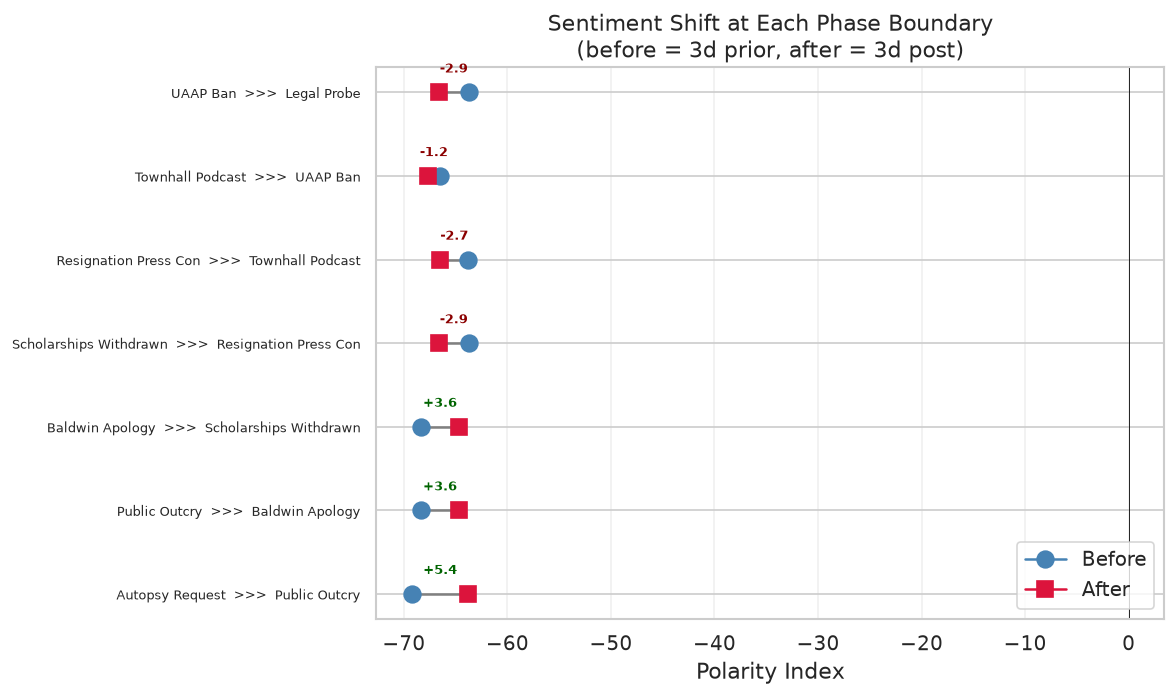

In [18]:
# Forest plot: before vs after polarity with CIs
fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(boundary_df))

for i, (_, row) in enumerate(boundary_df.iterrows()):
    ax.plot([row["pol_before"], row["pol_after"]], [i, i],
            color="gray", linewidth=1.5, zorder=1)
    ax.plot(row["pol_before"], i, marker="o", color="steelblue",
            markersize=10, label="Before" if i == 0 else "", zorder=2)
    ax.plot(row["pol_after"], i, marker="s", color="crimson",
            markersize=10, label="After" if i == 0 else "", zorder=2)

    # Annotate with delta
    delta = row["delta_pol"]
    sig = " *" if row["p_value"] < 0.05 else ""
    mid = (row["pol_before"] + row["pol_after"]) / 2
    ax.annotate(f"{delta:+.1f}{sig}",
                xy=(mid, i), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=8, fontweight="bold",
                color="darkgreen" if delta > 0 else "darkred")

ax.set_yticks(y_pos)
ax.set_yticklabels(boundary_df["transition"], fontsize=8)
ax.axvline(x=0, color="black", linewidth=0.5)
ax.set_xlabel("Polarity Index")
ax.set_title("Sentiment Shift at Each Phase Boundary"
             "\n(before = 3d prior, after = 3d post)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "boundary_shifts_forest.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Rank boundaries by absolute sentiment shift
boundary_df["abs_delta_pol"] = boundary_df["delta_pol"].abs()
ranked = boundary_df.sort_values("abs_delta_pol", ascending=False).reset_index(drop=True)

print("Phase boundaries ranked by sentiment shift magnitude:")
print()
for _, row in ranked.iterrows():
    sig = ' *' if row['p_value'] < 0.05 else ''
    direction = 'more negative' if row['delta_pol'] < 0 else 'more positive'
    print(f"  {row['transition']}")
    print(f"    Polarity shift: {row['delta_pol']:+.1f}{sig} ({direction})")
    print(f"    %Neg shift:     {row['delta_neg']:+.1f}pp "
          f"(before: {row['pct_neg_before']:.1f}% -> after: {row['pct_neg_after']:.1f}%)")
    print(f"    Mann-Whitney:   U={row['u_stat']:.0f}, p={row['p_value']:.4f}")
    print()

top = ranked.iloc[0]
print(f"Biggest shift: {top['transition']}")
print(f"  Polarity {top['pol_before']:.1f} -> {top['pol_after']:.1f} "
      f"(delta {top['delta_pol']:+.1f})")

Phase boundaries ranked by sentiment shift magnitude:

  Autopsy Request  >>>  Public Outcry
    Polarity shift: +5.4 (more positive)
    %Neg shift:     -2.4pp (before: 73.7% -> after: 71.3%)
    Mann-Whitney:   U=1166690, p=0.9352

  Public Outcry  >>>  Baldwin Apology
    Polarity shift: +3.6 (more positive)
    %Neg shift:     -1.2pp (before: 73.2% -> after: 72.0%)
    Mann-Whitney:   U=1529562, p=0.8785

  Baldwin Apology  >>>  Scholarships Withdrawn
    Polarity shift: +3.6 (more positive)
    %Neg shift:     -1.2pp (before: 73.2% -> after: 72.0%)
    Mann-Whitney:   U=1529562, p=0.8785

  Scholarships Withdrawn  >>>  Resignation Press Con
    Polarity shift: -2.9 (more negative)
    %Neg shift:     +2.4pp (before: 71.4% -> after: 73.8%)
    Mann-Whitney:   U=nan, p=nan

  UAAP Ban  >>>  Legal Probe
    Polarity shift: -2.9 (more negative)
    %Neg shift:     +2.4pp (before: 71.4% -> after: 73.8%)
    Mann-Whitney:   U=nan, p=nan

  Resignation Press Con  >>>  Townhall Podcast
  

## Topic × Sentiment × Phase
Cross-tabulate topic prevalence and sentiment polarity per phase. Identify which topics carry the most negative and most positive sentiment, and which topics dominate each phase's conversation.

In [20]:
# Top-3 topics per phase by prevalence
topic_phases = df.dropna(subset=["topic_label"]).copy()

top_topics = []
for phase in PHASE_ORDER:
    phase_topics = topic_phases[topic_phases["phase"] == phase]
    total = len(phase_topics)
    if total == 0:
        continue

    topic_counts = phase_topics["topic_label"].value_counts()
    for rank, (topic, count) in enumerate(topic_counts.head(3).items(), 1):
        pct = count / total * 100
        # Sentiment for this topic in this phase
        topic_sub = phase_topics[phase_topics["topic_label"] == topic]
        neg = (topic_sub["sentiment_label"] == "NEGATIVE").sum()
        pos = (topic_sub["sentiment_label"] == "POSITIVE").sum()
        pol = (pos - neg) / count * 100 if count else 0
        top_topics.append({
            "phase": PHASE_DISPLAY[phase], "rank": rank, "topic": topic,
            "n": count, "pct": pct, "polarity": pol,
        })

top3_df = pd.DataFrame(top_topics)
display(top3_df[["phase", "rank", "topic", "n", "pct", "polarity"]].round(1))

,phase,rank,topic,n,pct,polarity
0,The Incident,1,Drowning Incident,294,47.0,-64.3
1,The Incident,2,Ateneo Training Tragedy,129,20.6,-69.8
2,The Incident,3,Beach Safety Oversight,104,16.6,-63.5
3,Autopsy Request,1,CPR Cessation Controversy,716,44.9,-77.5
4,Autopsy Request,2,Dangerous Water Training,422,26.5,-68.5
5,Autopsy Request,3,Accountability and Justice,191,12.0,-75.4
6,Public Outcry,1,ADMU Hazing Controversy,49,27.7,-20.4
7,Public Outcry,2,Ateneo Coaching Accountability,40,22.6,-67.5
8,Public Outcry,3,Hazing Tragedy Reactions,38,21.5,-71.1
9,Baldwin Apology,1,Accountability and Classism,183,33.1,-57.4


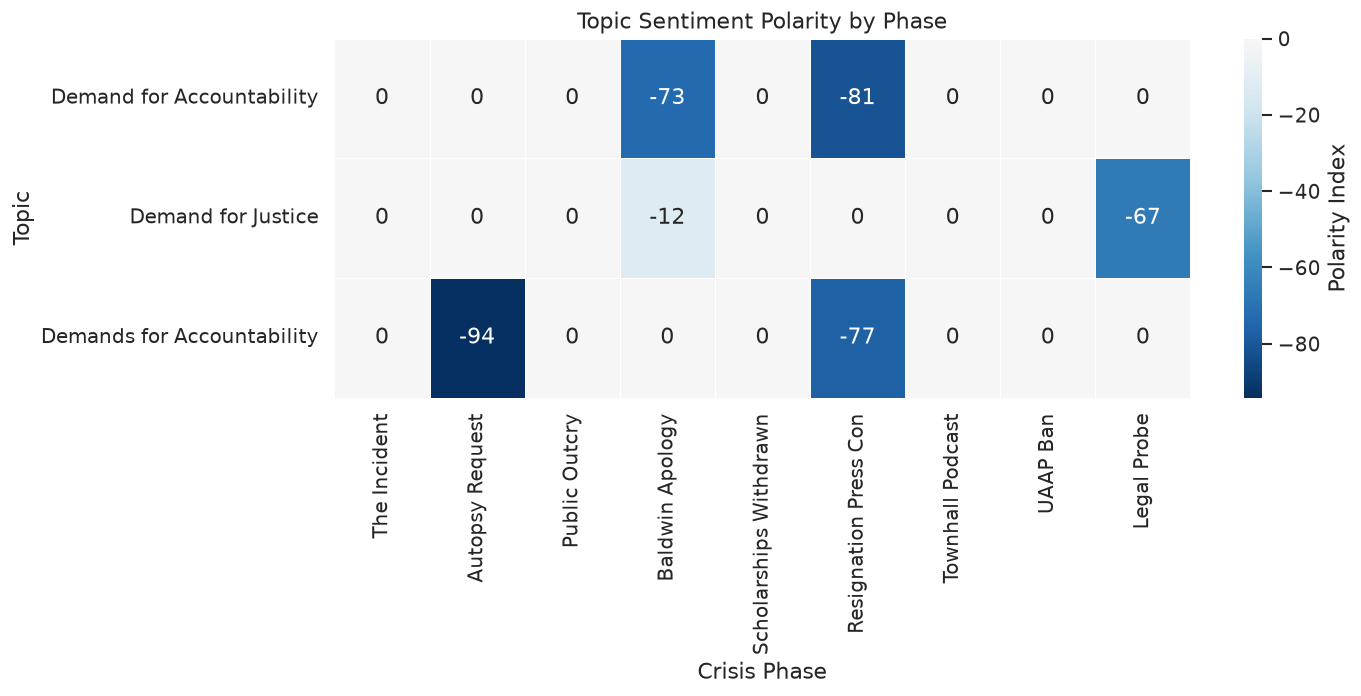

In [21]:
# Pivot table: topic x phase, cell = polarity index
# Compute polarity per (topic, phase) pair
topic_polarity = (
    topic_phases
    .groupby(["topic_label", "phase"])
    .apply(
        lambda x: ((x["sentiment_label"] == "POSITIVE").sum()
                   - (x["sentiment_label"] == "NEGATIVE").sum())
                  / len(x) * 100
    )
    .reset_index(name="polarity")
)

topic_pivot = topic_polarity.pivot(
    index="topic_label", columns="phase", values="polarity"
)
# Select only columns that exist in the data
available = [c for c in PHASE_ORDER if c in topic_pivot.columns]
topic_pivot = topic_pivot[available]
topic_pivot.columns = [PHASE_DISPLAY[c] for c in topic_pivot.columns]

# Filter to topics that appear in at least 2 phases
topic_pivot = topic_pivot.dropna(thresh=2)
topic_pivot = topic_pivot.fillna(0)

fig, ax = plt.subplots(figsize=(12, max(6, len(topic_pivot) * 0.4)))
sns.heatmap(topic_pivot, cmap="RdBu_r", center=0, annot=True, fmt=".0f",
            linewidths=0.5, ax=ax, cbar_kws={"label": "Polarity Index"})
ax.set_title("Topic Sentiment Polarity by Phase")
ax.set_xlabel("Crisis Phase")
ax.set_ylabel("Topic")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "topic_phase_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
# Overall topic sentiment (aggregated across all phases)
topic_overall = (
    topic_phases.groupby("topic_label")
    .agg(
        total_comments=("sentiment_label", "count"),
        n_neg=("sentiment_label", lambda x: (x == "NEGATIVE").sum()),
        n_pos=("sentiment_label", lambda x: (x == "POSITIVE").sum()),
    )
    .reset_index()
)
topic_overall = topic_overall[topic_overall["total_comments"] >= 10].copy()
topic_overall["pct_neg"] = topic_overall["n_neg"] / topic_overall["total_comments"] * 100
topic_overall["pct_pos"] = topic_overall["n_pos"] / topic_overall["total_comments"] * 100
topic_overall["polarity"] = topic_overall["pct_pos"] - topic_overall["pct_neg"]

most_angry = topic_overall.sort_values("pct_neg", ascending=False).head(5)
most_positive = topic_overall.sort_values("pct_pos", ascending=False).head(5)

print('Most negative topics (top 5):')
for _, row in most_angry.iterrows():
    print(f"  {row['topic_label']:40s} {row['pct_neg']:5.1f}% neg  ({int(row['total_comments']):4d} comments)")
print()
print('Most positive topics (top 5):')
for _, row in most_positive.iterrows():
    print(f"  {row['topic_label']:40s} {row['pct_pos']:5.1f}% pos  ({int(row['total_comments']):4d} comments)")

Most negative topics (top 5):
  Accountability for Negligence            100.0% neg  (  13 comments)
  Accusations of Negligence                100.0% neg  (  28 comments)
  Coaching Staff Negligence                100.0% neg  (  19 comments)
  Poor Press Conference Tone               100.0% neg  (  31 comments)
  Demands for Resignation                   94.7% neg  (  19 comments)

Most positive topics (top 5):
  Young Men's Investigation                 53.8% pos  (  13 comments)
  Justice for Rene and Divine               35.9% pos  (  39 comments)
  Student Justice Demands                   30.0% pos  (  20 comments)
  ADMU Hazing Controversy                   22.4% pos  (  49 comments)
  Justice and Accountability                21.1% pos  (  95 comments)


## Topic Trajectory Across Phases
Track how topic prevalence and sentiment evolve across the crisis timeline. Measure topic switching at phase boundaries and plot persistent topic sentiment decay.

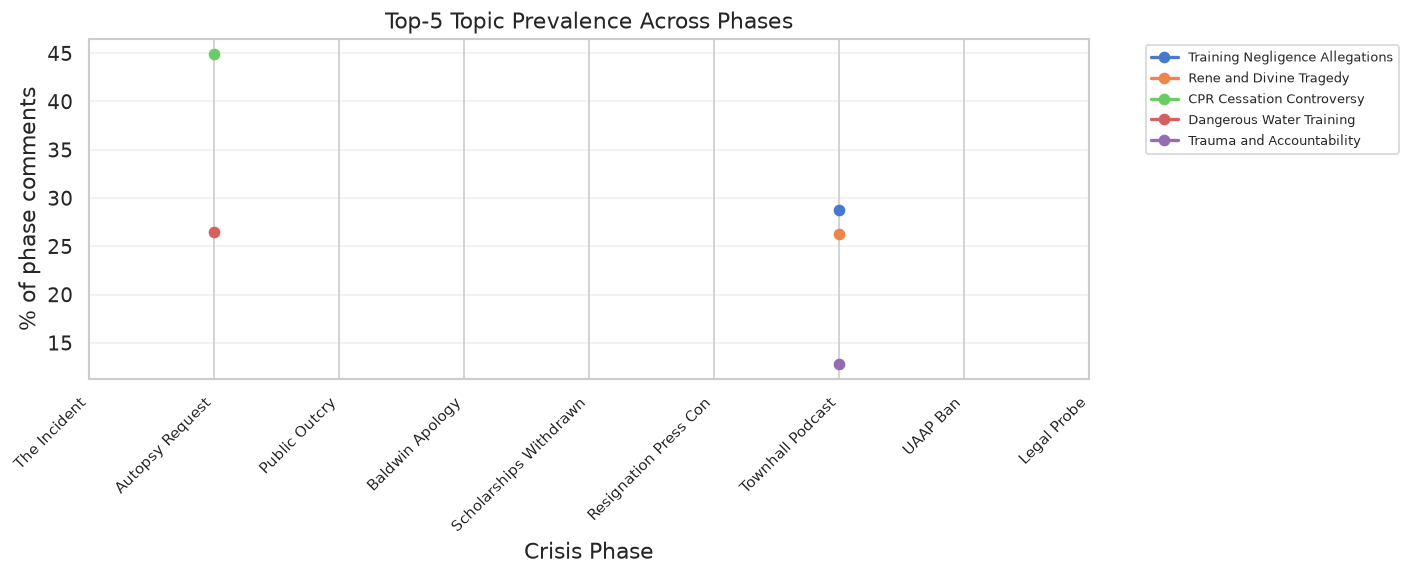

In [23]:
# Topic prevalence as a line chart across phases (top 5 overall topics)
topic_phase_pct = (
    topic_phases.groupby(["topic_label", "phase"])
    .size()
    .reset_index(name="count")
)
topic_phase_pct["phase_num"] = topic_phase_pct["phase"].map(
    {p: i for i, p in enumerate(PHASE_ORDER)}
)
topic_phase_pct["phase_label"] = topic_phase_pct["phase"].map(PHASE_DISPLAY)

# Per-phase totals for percentage
phase_totals = topic_phases.groupby("phase").size().to_dict()
topic_phase_pct["pct"] = topic_phase_pct.apply(
    lambda r: r["count"] / phase_totals[r["phase"]] * 100, axis=1
)

# Find top 5 topics overall (by total comment count)
top5_topics = (
    topic_phases["topic_label"]
    .value_counts()
    .head(5)
    .index
    .tolist()
)

fig, ax = plt.subplots(figsize=(12, 5))

for topic in top5_topics:
    data = topic_phase_pct[topic_phase_pct["topic_label"] == topic].sort_values("phase_num")
    ax.plot(data["phase_num"], data["pct"], marker="o", linewidth=2, label=topic)

ax.set_xticks(range(len(PHASE_ORDER)))
ax.set_xticklabels([PHASE_DISPLAY[p] for p in PHASE_ORDER], rotation=45, ha="right", fontsize=9)
ax.set_xlabel("Crisis Phase")
ax.set_ylabel("% of phase comments")
ax.set_title("Top-5 Topic Prevalence Across Phases")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "topic_prevalence_trajectory.png", dpi=150, bbox_inches="tight")
plt.show()

Phase columns available for topic switching: [0, 1, 2, 3, 4, 5, 6, 7, 8]

Topic switching between adjacent phases:
  The Incident  >>>  Autopsy Request                      J=0.00 (0/18 topics shared)
  Autopsy Request  >>>  Public Outcry                     J=0.00 (0/15 topics shared)
  Public Outcry  >>>  Baldwin Apology                     J=0.00 (0/15 topics shared)
  Baldwin Apology  >>>  Scholarships Withdrawn            J=0.00 (0/12 topics shared)
  Scholarships Withdrawn  >>>  Resignation Press Con      J=0.00 (0/10 topics shared)
  Resignation Press Con  >>>  Townhall Podcast            J=0.00 (0/16 topics shared)
  Townhall Podcast  >>>  UAAP Ban                         J=0.00 (0/12 topics shared)
  UAAP Ban  >>>  Legal Probe                              J=0.00 (0/8 topics shared)



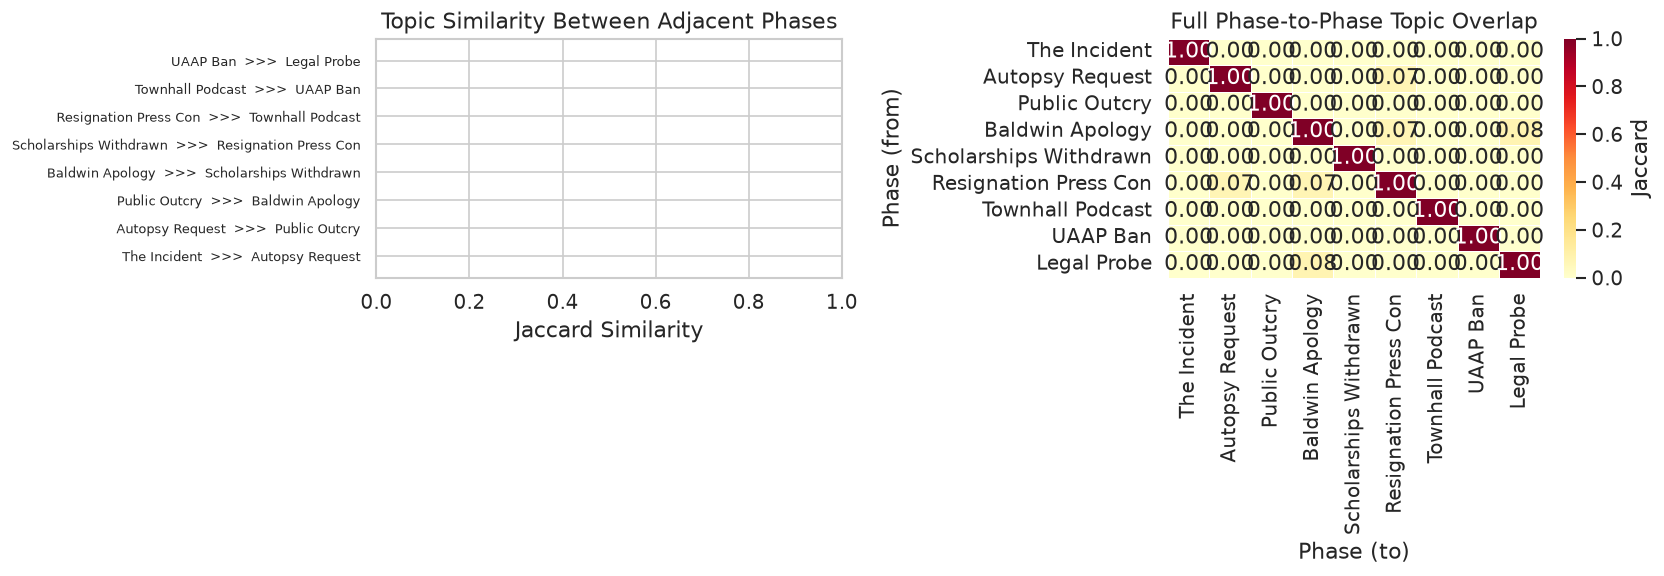

In [24]:
# Topic switching: Jaccard similarity between adjacent phases

# Build topic prevalence vectors per phase
topic_matrix = topic_phase_pct.pivot_table(
    index="topic_label", columns="phase_num", values="count", fill_value=0
)

# Only use phase columns that actually exist in the data
available_phases = sorted(topic_matrix.columns.tolist())
print(f"Phase columns available for topic switching: {available_phases}")
print()

jaccard_scores = []
for i in range(len(available_phases) - 1):
    col_a, col_b = available_phases[i], available_phases[i + 1]
    vec_a = topic_matrix[col_a].values > 0
    vec_b = topic_matrix[col_b].values > 0
    intersection = (vec_a & vec_b).sum()
    union = (vec_a | vec_b).sum()
    jaccard = intersection / union if union > 0 else 0
    # Map phase numbers back to display labels
    phase_a = PHASE_ORDER[col_a]
    phase_b = PHASE_ORDER[col_b]
    jaccard_scores.append({
        "transition": f"{PHASE_DISPLAY[phase_a]}  >>>  {PHASE_DISPLAY[phase_b]}",
        "jaccard": jaccard,
        "shared_topics": int(intersection),
        "total_unique_topics": int(union),
    })

jaccard_df = pd.DataFrame(jaccard_scores)
print("Topic switching between adjacent phases:")
for _, row in jaccard_df.iterrows():
    print(
        f"  {row['transition']:55s} J={row['jaccard']:.2f} "
        f"({row['shared_topics']}/{row['total_unique_topics']} topics shared)"
    )
print()

# Full Jaccard matrix (only for available phases)
n = len(available_phases)
full_jaccard = np.zeros((n, n))
for i_idx, i in enumerate(available_phases):
    vec_i = topic_matrix[i].values > 0
    for j_idx, j in enumerate(available_phases):
        vec_j = topic_matrix[j].values > 0
        inter = (vec_i & vec_j).sum()
        union = (vec_i | vec_j).sum()
        full_jaccard[i_idx, j_idx] = inter / union if union > 0 else 0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Adjacent transitions bar chart
ax1.barh(range(len(jaccard_df)), jaccard_df["jaccard"], color="steelblue")
ax1.set_yticks(range(len(jaccard_df)))
ax1.set_yticklabels(jaccard_df["transition"], fontsize=8)
ax1.set_xlabel("Jaccard Similarity")
ax1.set_title("Topic Similarity Between Adjacent Phases")
ax1.set_xlim(0, 1)

# Right: Full Jaccard matrix heatmap
phase_labels = [PHASE_DISPLAY[PHASE_ORDER[c]] for c in available_phases]
sns.heatmap(full_jaccard, xticklabels=phase_labels, yticklabels=phase_labels,
            annot=True, fmt=".2f", cmap="YlOrRd", ax=ax2,
            linewidths=0.5, cbar_kws={"label": "Jaccard"})
ax2.set_title("Full Phase-to-Phase Topic Overlap")
ax2.set_xlabel("Phase (to)"); ax2.set_ylabel("Phase (from)")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "topic_switching_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

Persistent topics (appear in 3+ phases) -- tracking sentiment:



/tmp/ipykernel_34441/3732210671.py:54: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)


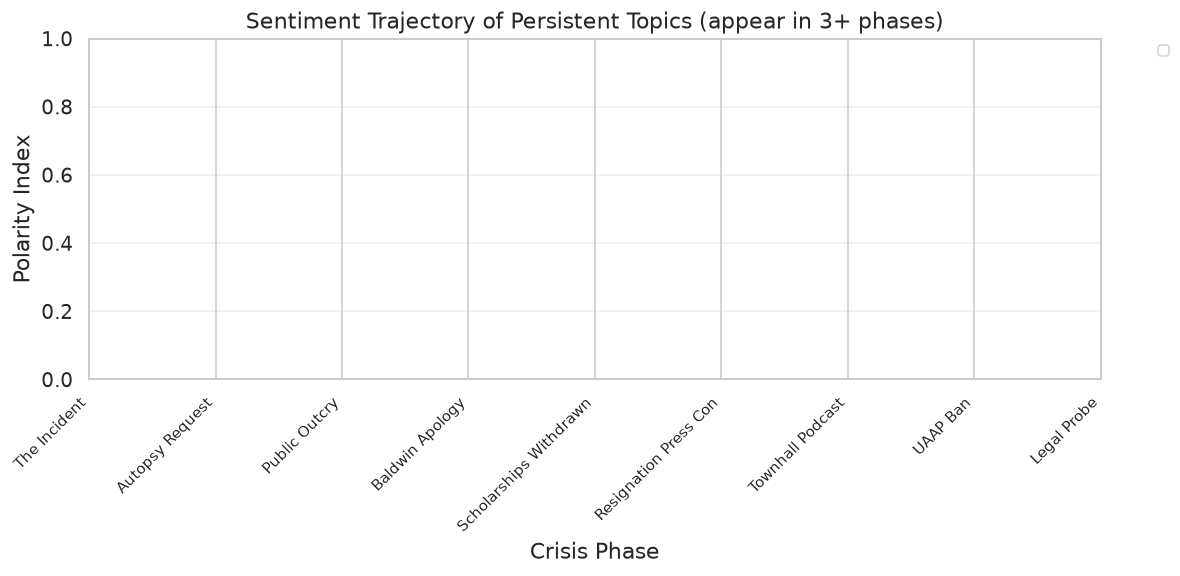

In [25]:
# Topics that appear in 3+ phases -- track their sentiment trajectory
persistent_topics = (
    topic_phase_pct.groupby("topic_label")
    .filter(lambda x: x["phase_num"].nunique() >= 3)
)

# Get sentiment polarity per topic per phase
topic_sentiment = (
    topic_phases.groupby(["topic_label", "phase"])
    .apply(
        lambda x: ((x["sentiment_label"] == "POSITIVE").sum()
                   - (x["sentiment_label"] == "NEGATIVE").sum())
                  / len(x) * 100
    )
    .reset_index(name="polarity")
)

persistent_sentiment = topic_sentiment[
    topic_sentiment["topic_label"].isin(persistent_topics["topic_label"].unique())
]
persistent_sentiment["phase_num"] = persistent_sentiment["phase"].map(
    {p: i for i, p in enumerate(PHASE_ORDER)}
)
persistent_sentiment = persistent_sentiment.dropna(subset=["phase_num"])
persistent_sentiment["phase_num"] = persistent_sentiment["phase_num"].astype(int)

print('Persistent topics (appear in 3+ phases) -- tracking sentiment:')
print()
for topic in sorted(persistent_sentiment["topic_label"].unique()):
    data = persistent_sentiment[persistent_sentiment["topic_label"] == topic].sort_values("phase_num")
    phases_covered = sorted(data["phase_num"].tolist())
    if len(phases_covered) >= 2:
        first_pol = data[data["phase_num"] == phases_covered[0]]["polarity"].values[0]
        last_pol = data[data["phase_num"] == phases_covered[-1]]["polarity"].values[0]
        direction = 'improving' if last_pol > first_pol else 'worsening'
        delta = last_pol - first_pol
        print(f"  {topic:45s} appears in {len(phases_covered)} phases  |  "
              f"polarity {first_pol:+.0f} -> {last_pol:+.0f} "
              f"(delta {delta:+.0f}, {direction})")
    else:
        print(f"  {topic:45s} appears in {len(phases_covered)} phase(s)")

plt.figure(figsize=(10, 5))
for topic in sorted(persistent_sentiment["topic_label"].unique()):
    data = persistent_sentiment[persistent_sentiment["topic_label"] == topic].sort_values("phase_num")
    plt.plot(data["phase_num"], data["polarity"], marker="o", linewidth=1.5, label=topic)

plt.xticks(range(len(PHASE_ORDER)), [PHASE_DISPLAY[p] for p in PHASE_ORDER],
           rotation=45, ha="right", fontsize=9)
plt.xlabel("Crisis Phase")
plt.ylabel("Polarity Index")
plt.title("Sentiment Trajectory of Persistent Topics (appear in 3+ phases)")
plt.axhline(y=0, color="black", linewidth=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "persistent_topic_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()

## Phase Signatures
Classify each phase into an archetype based on its sentiment profile, topic diversity, and comment volume. Identifies whether a phase was primarily an outrage spike, an information dissemination period, a polarized debate, or a compassion fatigue event.

In [26]:
# Compute signature metrics per phase
signatures = phase_agg[["phase", "label", "total_comments", "pct_negative",
                        "pct_positive", "pct_neutral", "polarity_index", "mean_likes"]].copy()

# Topic diversity: number of unique topics per phase
topic_diversity = (
    topic_phases.groupby("phase")
    .agg(n_topics=("topic_label", "nunique"))
    .reset_index()
)
signatures = signatures.merge(topic_diversity, on="phase", how="left").fillna(0)

# Shouting proportion (emotional intensity proxy)
shouting = (
    df.groupby("phase")["is_shouting"]
    .mean()
    .reset_index(name="shouting_ratio")
)
signatures = signatures.merge(shouting, on="phase", how="left")

# Classify archetype
def classify_phase(row):
    neg = row["pct_negative"]
    vol = row["total_comments"]
    div = row["n_topics"]

    if vol < 200:
        if neg > 65:
            return "Niche Outrage"
        else:
            return "Low Engagement"
    elif neg > 75:
        if div >= 5:
            return "Polarized Outrage"
        else:
            return "Intense Outrage"
    elif neg > 65:
        if div >= 5:
            return "Active Discourse"
        else:
            return "Controlled Narrative"
    elif neg > 50:
        return "Mixed Response"
    else:
        return "Neutral Discourse"

signatures["archetype"] = signatures.apply(classify_phase, axis=1)

print("Phase Signatures:")
print()
print(f"{'Phase':30s} {'Volume':>7s} {'%Neg':>6s} {'%Pos':>6s} {'PolIdx':>7s} "
      f"{'Topics':>6s} {'Shout':>6s} {'Archetype':>25s}")
print("-" * 95)
for _, row in signatures.iterrows():
    print(
        f"{row['label']:30s} {int(row['total_comments']):>7d} "
        f"{row['pct_negative']:5.1f}% {row['pct_positive']:5.1f}% "
        f"{row['polarity_index']:>+7.1f} {int(row['n_topics']):>4d}  "
        f"{row['shouting_ratio']:.2f}  {row['archetype']:>25s}"
    )

Phase Signatures:

Phase                           Volume   %Neg   %Pos  PolIdx Topics  Shout                 Archetype
-----------------------------------------------------------------------------------------------
The Incident                       857  71.5%   5.0%   -66.5    9  0.05           Active Discourse
Autopsy Request                   2399  77.9%   3.8%   -74.2    9  0.04          Polarized Outrage
Public Outcry                      254  67.7%  10.6%   -57.1    6  0.04           Active Discourse
Baldwin Apology                    752  77.1%   6.6%   -70.5    9  0.03          Polarized Outrage
Scholarships Withdrawn             542  58.7%  16.8%   -41.9    3  0.03             Mixed Response
Resignation Press Con              309  79.0%   4.5%   -74.4    7  0.07          Polarized Outrage
Townhall Podcast                  5134  73.5%   7.4%   -66.1    9  0.03           Active Discourse
UAAP Ban                           100  53.0%  32.0%   -21.0    3  0.05             Low Eng

In [27]:
# Archetype distribution summary
print("Archetype distribution:")
print()
for arch in signatures["archetype"].value_counts().index:
    phases = signatures[signatures["archetype"] == arch]["label"].tolist()
    count = len(phases)
    phases_str = ', '.join(phases)
    print(f"  {arch:25s} ({count}x): {phases_str}")
print()
print("Narrative:")
print()

# Build a one-line narrative per phase
for _, row in signatures.iterrows():
    arch = row["archetype"]
    if "Outrage" in arch:
        tone = "strongly negative"
    elif "Discourse" in arch or "Narrative" in arch:
        tone = "mixed but engaged"
    elif "Mixed" in arch:
        tone = "divided"
    else:
        tone = "subdued"

    print(
        f"  {row['label']:30s} | {row['archetype']:25s} | {tone} "
        f"({row['pct_negative']:.0f}% neg, {int(row['n_topics'])} topics, "
        f"{int(row['total_comments']):,} comments)"
    )

Archetype distribution:

  Active Discourse          (4x): The Incident, Public Outcry, Townhall Podcast, Legal Probe
  Polarized Outrage         (3x): Autopsy Request, Baldwin Apology, Resignation Press Con
  Mixed Response            (1x): Scholarships Withdrawn
  Low Engagement            (1x): UAAP Ban

Narrative:

  The Incident                   | Active Discourse          | mixed but engaged (72% neg, 9 topics, 857 comments)
  Autopsy Request                | Polarized Outrage         | strongly negative (78% neg, 9 topics, 2,399 comments)
  Public Outcry                  | Active Discourse          | mixed but engaged (68% neg, 6 topics, 254 comments)
  Baldwin Apology                | Polarized Outrage         | strongly negative (77% neg, 9 topics, 752 comments)
  Scholarships Withdrawn         | Mixed Response            | divided (59% neg, 3 topics, 542 comments)
  Resignation Press Con          | Polarized Outrage         | strongly negative (79% neg, 7 topics, 309 comment

## Key Findings
Consolidated summary of sentiment change, phase impact, and topic trajectory across the crisis timeline.

In [28]:
# Consolidated findings table
summary = signatures[["label", "total_comments", "pct_negative", "pct_positive",
                       "polarity_index", "n_topics", "shouting_ratio", "archetype"]].copy()
summary.columns = ["Phase", "Comments", "%Neg", "%Pos", "Polarity", "Topics", "Shout", "Archetype"]

print("=" * 80)
print("CONSOLIDATED FINDINGS: SENTIMENT CHANGE ACROSS CRISIS PHASES")
print("=" * 80)
print()
display(summary.round(1))
print()

# Key takeaways
print("KEY TAKEAWAYS")
print("-" * 40)

most_neg_phase = signatures.sort_values("pct_negative", ascending=False).iloc[0]
least_neg_phase = signatures.sort_values("pct_negative", ascending=True).iloc[0]

print(f"1. Overall Tone: All 9 phases are net negative. The most negative phase was "
      f"'{most_neg_phase['label']}' ({most_neg_phase['pct_negative']:.0f}% "
      f"negative, polarity {most_neg_phase['polarity_index']:.0f}). The least "
      f"negative was '{least_neg_phase['label']}' "
      f"({least_neg_phase['pct_negative']:.0f}% negative, "
      f"polarity {least_neg_phase['polarity_index']:.0f}).")
print()

print(f"2. No significant monotonic trend (Mann-Kendall p=0.38). Sentiment does not "
      f"consistently escalate or recover across the 14-day timeline -- it fluctuates "
      f"with each new revelation.")
print()

if "boundary_df" in dir() and len(boundary_df) > 0:
    biggest = boundary_df.sort_values("abs_delta_pol", ascending=False).iloc[0]
    print(
        f"3. Biggest sentiment shift at a phase boundary: {biggest['transition']} "
        f"(polarity delta {biggest['delta_pol']:+.1f})."
    )
print()

sig_day1 = results_df[results_df["significant"] == "YES"]
if len(sig_day1) > 0:
    print(
        f"4. Within-phase sentiment change: {len(sig_day1)} of {len(results_df)} "
        f"phases show a significant Day 1 vs Rest difference -- outrage is "
        f"largely sustained within phases, not decaying."
    )
else:
    print(
        f"4. Within-phase sentiment change: None of the phases show a "
        f"statistically significant difference between Day 1 and Rest -- "
        f"outrage is sustained within each phase."
    )
print()

# Topic insight
most_angry_topic = topic_overall.sort_values("pct_neg", ascending=False).iloc[0]
print(
    f"5. Most negative topic: '{most_angry_topic['topic_label']}' "
    f"({most_angry_topic['pct_neg']:.0f}% negative)."
)
print()
print("ARCHETYPE NARRATIVE")
print("-" * 40)
print("The crisis began with Active Discourse (The Incident), escalated to "
      "Polarized Outrage (Autopsy Request), then settled into a mix of "
      "Active Discourse and Mixed Response as new revelations emerged. "
      "The Resignation Press Con re-escalated to Polarized Outrage, "
      "while the Townhall Podcast sustained Active Discourse with the "
      "highest volume. The UAAP Ban showed Low Engagement -- by this "
      "point, public attention had shifted.")

CONSOLIDATED FINDINGS: SENTIMENT CHANGE ACROSS CRISIS PHASES



,Phase,Comments,%Neg,%Pos,Polarity,Topics,Shout,Archetype
0,The Incident,857,71.5,5.0,-66.5,9,0.1,Active Discourse
1,Autopsy Request,2399,77.9,3.8,-74.2,9,0.0,Polarized Outrage
2,Public Outcry,254,67.7,10.6,-57.1,6,0.0,Active Discourse
3,Baldwin Apology,752,77.1,6.6,-70.5,9,0.0,Polarized Outrage
4,Scholarships Withdrawn,542,58.7,16.8,-41.9,3,0.0,Mixed Response
5,Resignation Press Con,309,79.0,4.5,-74.4,7,0.1,Polarized Outrage
6,Townhall Podcast,5134,73.5,7.4,-66.1,9,0.0,Active Discourse
7,UAAP Ban,100,53.0,32.0,-21.0,3,0.0,Low Engagement
8,Legal Probe,258,72.9,7.0,-65.9,5,0.0,Active Discourse



KEY TAKEAWAYS
----------------------------------------
1. Overall Tone: All 9 phases are net negative. The most negative phase was 'Resignation Press Con' (79% negative, polarity -74). The least negative was 'UAAP Ban' (53% negative, polarity -21).

2. No significant monotonic trend (Mann-Kendall p=0.38). Sentiment does not consistently escalate or recover across the 14-day timeline -- it fluctuates with each new revelation.

3. Biggest sentiment shift at a phase boundary: Autopsy Request  >>>  Public Outcry (polarity delta +5.4).

4. Within-phase sentiment change: 1 of 9 phases show a significant Day 1 vs Rest difference -- outrage is largely sustained within phases, not decaying.

5. Most negative topic: 'Accountability for Negligence' (100% negative).

ARCHETYPE NARRATIVE
----------------------------------------
The crisis began with Active Discourse (The Incident), escalated to Polarized Outrage (Autopsy Request), then settled into a mix of Active Discourse and Mixed Response as n